Paquetes necesarios

In [2]:
import cv2  
import numpy as np
import matplotlib.pyplot as plt
import csv

Las formas localizadas tienen distintas características geométricas, que pueden estimarse a partir de sus contornos. Más información en la [documentación de OpenCV](https://docs.opencv.org/4.x/dd/d49/tutorial_py_contour_features.html).

TAREA: Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia impicaríaj en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y mo¡ilímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien 
no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas?
Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc. 



In [2]:


monedas = {200: 25.75, 100: 23.25, 50: 24.35, 20: 22.25, 10: 19.75, 5: 21.25, 2: 18.75, 1: 16.25}
tecla_monedas = {49: 1, 50: 2, 51: 5, 52: 10, 53: 20, 54: 50, 55: 100, 56: 200}

escala = None
keyboardKey = None
radio = None
coords = []

def on_mouse_click(event, x, y, flags, param):
    if event == cv2.EVENT_LBUTTONDOWN:
        coords.append((x, y))

cv2.namedWindow("Monedas")
video = cv2.VideoCapture(0)  # Inicia la cámara

cv2.setMouseCallback("Monedas", on_mouse_click)

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))

kernel_abrir = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (41, 41))

while True:
    ret, frame = video.read()
    if not ret:
        break

    img = frame.copy()
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


    img_gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    img_gris = cv2.GaussianBlur(img_gris, (7, 7), 0)
    umbral = 200    

    th1,img_th1 = cv2.threshold(img_gris,umbral,255,cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    img_th1 = cv2.morphologyEx(img_th1, cv2.MORPH_CLOSE, kernel)
    img_th1 = cv2.morphologyEx(img_th1, cv2.MORPH_OPEN, kernel_abrir)
    contornos2, hierarchy2 = cv2.findContours(img_th1,
            cv2.RETR_EXTERNAL ,
            cv2.CHAIN_APPROX_SIMPLE)
    img_cont = np.zeros(img_rgb.shape, dtype=np.uint8)
    img_cont = cv2.copyMakeBorder(img_cont, 0, 0, 0, 250, cv2.BORDER_CONSTANT, value=(0, 0, 0))
    contourData = []
    for c in contornos2:
        c = cv2.convexHull(c)
        area = cv2.contourArea(c)
        per = cv2.arcLength(c, True)
        if 1500 < area < 25000 and per > 0 and 4 * np.pi * area / per**2 > 0.75:

                    #Mínimo círculo que contiene al contorno
            (cx,cy),r = cv2.minEnclosingCircle(c)
            contourData.append((r, (cx,cy)))
                    #Dibuja los contornos
            cv2.drawContours(img_cont, [c], -1, (255,255,255), -1)
            cv2.circle(img_cont,(int(cx), int(cy)),
                        5,(0, 0, 255), -1)

    tecla_c = cv2.waitKey(1) & 0xFF

    if escala is None:
        cv2.putText(frame, "Pulsa la tecla 'c' para calibrar", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)

    if tecla_c == ord('c'):
        keyboardKey = None
        radio = None
        coords = []


        cv2.putText(img_cont, "Click en una moneda y\n selecciona la tecla:\n 1 = 1 cent\n 2 = 2 cent\n 3 = 5 cent\n 4 = 10 cent\n 5 = 20 cent\n 6 = 50 cent\n 7 = 1 euro\n 8 = 2 euros", (frame.shape[1] + 10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)


        while not coords:
            cv2.imshow("Monedas", img_cont)
            tecla = cv2.waitKey(1) & 0xFF
            if tecla == 27:
                break

        if coords:
            while True:
                cv2.imshow("Monedas", img_cont)
                tecla = cv2.waitKey(1) & 0xFF
                if tecla == 27:  # Esc cancela
                    break
                elif tecla in tecla_monedas:
                    keyboardKey = tecla
                    break

        if keyboardKey is not None:
            value = tecla_monedas[keyboardKey]
            diametro = monedas[value]

            for r, (cx, cy) in contourData:
                for x, y in coords:
                    if (cx - x) ** 2 + (cy - y) ** 2 <= r ** 2:
                        radio= r
                        print(f"Moneda seleccionada: Radio={r}, Centro=({cx}, {cy})")
                        print(f"Valor: {value}, Diámetro: {diametro}")
                        break

            if radio is not None:
                r_2 = diametro / 2
                escala = radio / r_2
                print(f"Escala: {escala}")

    if escala is not None:
        d_medidos_escalados = [(r * 2) / escala for r, _ in contourData]
        suma_total = 0
        for d in d_medidos_escalados:
            mejor = min(monedas.keys(), key=lambda x: abs(monedas[x] - d))
            if abs(monedas[mejor] - d) < 1.0:
                suma_total += mejor
        cv2.putText(frame, f"Total: {suma_total/100:.2f} euros", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
        cv2.putText(frame, "'c' = recalibrar", (10, 60), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)

    cv2.imshow("Umbral", img_th1)
    for c in contornos2:
        a = cv2.contourArea(c)
        if a > 300:
            p = cv2.arcLength(c, True)
            print(f"area={a:.0f} circ={4*np.pi*a/p**2 if p else 0:.2f}")
    cv2.imshow("Monedas", frame)

    if tecla_c == 27:  # Presiona 'Esc' para salir
        break

# Fuera del bucle y sobre el objeto "video"
video.release()
cv2.destroyAllWindows()

area=14042 circ=0.64
area=165694 circ=0.34
area=14340 circ=0.63
area=167651 circ=0.34
area=14701 circ=0.65
area=168482 circ=0.34
area=9066 circ=0.61
area=161891 circ=0.35
area=8124 circ=0.61
area=6978 circ=0.67
area=152880 circ=0.48
area=8124 circ=0.61
area=6978 circ=0.67
area=152880 circ=0.48
area=7973 circ=0.61
area=8079 circ=0.70
area=154845 circ=0.48
area=7973 circ=0.61
area=8079 circ=0.70
area=154845 circ=0.48
area=758 circ=0.68
area=7841 circ=0.59
area=7418 circ=0.65
area=137997 circ=0.37
area=769 circ=0.69
area=6232 circ=0.74
area=7045 circ=0.68
area=127701 circ=0.28
area=769 circ=0.69
area=6232 circ=0.74
area=7045 circ=0.68
area=127701 circ=0.28
area=5662 circ=0.81
area=6968 circ=0.70
area=126186 circ=0.27
area=5662 circ=0.81
area=6968 circ=0.70
area=126186 circ=0.27
area=8656 circ=0.49
area=7326 circ=0.71
area=128942 circ=0.27
area=8656 circ=0.49
area=7326 circ=0.71
area=128942 circ=0.27
area=8396 circ=0.45
area=7150 circ=0.70
area=130492 circ=0.26
area=8398 circ=0.52
area=931

La segunda tarea plantea la clasificación de microplásticos en una imagen real. Dado que el mundo real es muy variado, las imágenes no siempre se capturan con unas condiciones de iluminación tan buenas o controladas. Ejemplo con aplicación de variantes de umbralizados ofrecidas por OpenCV sobre una imagen de muestras de microplásticos.

Umbral escogido  197.0


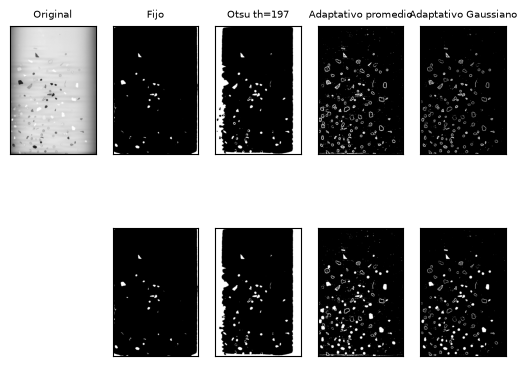

In [3]:
#Carga imagen directamente en grises
imgorig = cv2.imread('MPs_test.jpg', cv2.IMREAD_GRAYSCALE) 

img = cv2.GaussianBlur(imgorig,(5,5),0)

#Umbralizados
ret,imth1 = cv2.threshold(img,150,255,cv2.THRESH_BINARY_INV)
thotsu,imth2 = cv2.threshold(img,0,255,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)
print('Umbral escogido ', thotsu)
imth3 = cv2.adaptiveThreshold(img,255,cv2.ADAPTIVE_THRESH_MEAN_C,\
            cv2.THRESH_BINARY,11,2)
imth4 = cv2.adaptiveThreshold(img,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,\
            cv2.THRESH_BINARY,11,2)
 
titles = ['Original', 'Fijo','Otsu th='+str(int(thotsu)),
            'Adaptativo promedio', 'Adaptativo Gaussiano']
images = [img, imth1, imth2, 255 - imth3, 255 - imth4]
 
for i in range(5):
    plt.subplot(2,5,i+1),plt.imshow(images[i],'gray')
    plt.title(titles[i], fontsize=7)
    plt.xticks([]),plt.yticks([])

    #Obtiene únicamente los contornos externos
    if i>0:
        res,imth = cv2.threshold(images[i],120,255,cv2.THRESH_BINARY)
        contornos, hierarchy= cv2.findContours(imth, 
        cv2.RETR_EXTERNAL , 
        cv2.CHAIN_APPROX_SIMPLE)  
        img_cont = np.zeros(img.shape)
        cv2.drawContours(img_cont, contornos, -1, (255,255,255), -1)  
        plt.subplot(2,5,i+6),plt.imshow(img_cont,'gray')
        plt.xticks([]),plt.yticks([])
plt.show()

Para esta imagen de muestras de microplásticos tenemos una anotación (que puede contener errores) de la tipología de las partículas. Esta será la imagen de test en los experimentos posteriores, no puedes hacer uso de esta imagen para entrenar tu clasificador, solo par evaluarlo

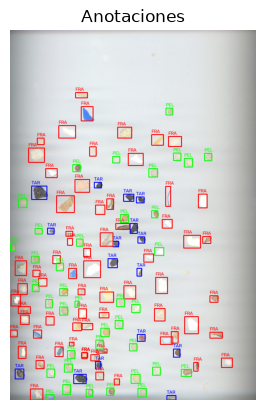

In [4]:
# Imagen y anotaciones
imagen = "MPs_test.jpg"          # Imagen original
csv_file = "MPs_test_bbs.csv"  # CSV con coordenadas y tipología

# Colores de cada clase
colores = {
    "FRA": (0, 0, 255),   # Rojo 
    "PEL": (0, 255, 0),   # Verde
    "TAR": (255, 0, 0)    # Azul
}

# Imagen
img = cv2.imread(imagen)

# Cara csv y dibujar rectángulos
with open(csv_file, newline="") as file:
    reader = csv.DictReader(file)
    for row in reader:
        etiqueta = row["label"]
        x_min, y_min, x_max, y_max = map(int, [row["x_min"], row["y_min"], row["x_max"], row["y_max"]])
        
        # Color según etiqueta
        color = colores.get(etiqueta, (0, 0, 0))  # negro por defecto si no encuentra
        
        # Dibujar rectángulo
        cv2.rectangle(img, (x_min, y_min), (x_max, y_max), color, 2)
        
        # Etiqueta 
        cv2.putText(img, etiqueta, (x_min, y_min - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)

# Visualiza resultado
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Anotaciones")
plt.axis('off')
plt.show()


##Muestras de entrenamiento

Text(0.5, 1.0, 'Alquitrán')

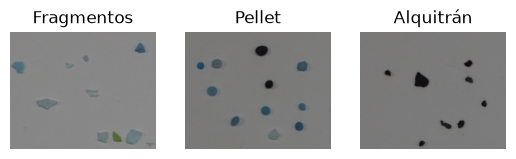

In [5]:
#Cargamos tres subimágenes, por simplicidad, de cada uno de los tres tipos considerados (reiterar que el alquitrán no es microplástico)
imgF = cv2.imread('FRA.png') 
imgP = cv2.imread('PEL.png') 
imgT = cv2.imread('TAR.png') 

#Mostramos
plt.subplot(131)
plt.axis("off")
plt.imshow(imgF) 
plt.title('Fragmentos')
plt.subplot(132)
plt.axis("off")
plt.imshow(imgP) 
plt.title('Pellet')
plt.subplot(133)
plt.axis("off")
plt.imshow(imgT) 
plt.title('Alquitrán')

El objetivo de la siguiente tarea, descrita más abajo, es desarrollar tu propio clasificador basado únicamente en heurísticas basadas en características geométricas y/o de apariencia, a partir de las imágenes completas de las partículas de cada tipo, debiendo mostrar la bondad del clasificador haciendo uso de métricas para ello sobre las anotaciones de la imagen de test *MPs_test.png*. La siguiente celda obtiene varias métricas para un conjunto de datos imaginario (y con etiquetas aleatorias). Si bien las trataremos con más detalle en teoría, muestro un repertorio de ellas, dando más peso a la matriz de confusión. La ejecución de la celda requiere instalar el paquete scikit-learn.

¿Qué es una matriz de confusión?
Se utiliza para mostrar el comportamiento de un clasificador para las distintas clases conocidas, se relacionan las etiquetas de las muestras anotadas frente a las predichas por el clasificador. Se busca una matriz diagonal, pero la perfección es infrecuente.

El siguiente ejemplo, muestra el modo de obtener la matriz de confusión para un hipotético problema con cuatro clases, y valores de anotación (variable y) y predicción (variable y_pred) obtenidos de forma aleatoria.

Anotaciones  [2, 2, 2, 1, 2, 3, 1, 0, 0, 2, 0, 0, 3, 2, 0, 2, 1, 3, 2, 1, 2, 2, 1, 3, 3, 1, 0, 3, 0, 1, 0, 1, 2, 0, 3, 3, 1, 0, 3, 2, 2, 0, 3, 3, 2, 1, 3, 1, 2, 3, 3, 0, 1, 3, 1, 0, 0, 3, 3, 1, 0, 1, 2, 1, 2, 2, 1, 1, 2, 1, 2, 3, 1, 3, 3, 1, 0, 3, 3, 3, 3, 1, 2, 1, 1, 2, 1, 1, 2, 3, 1, 2, 3, 0, 0, 2, 3, 1, 1, 0]
Predicciones  [0, 1, 1, 2, 0, 3, 1, 3, 0, 3, 3, 2, 2, 1, 3, 1, 2, 1, 2, 0, 1, 1, 2, 1, 2, 2, 1, 3, 1, 3, 2, 3, 2, 3, 0, 3, 1, 2, 0, 3, 2, 1, 1, 0, 2, 3, 0, 0, 0, 3, 2, 1, 1, 1, 0, 2, 2, 2, 3, 1, 2, 2, 1, 2, 3, 3, 3, 2, 2, 1, 2, 3, 0, 2, 2, 3, 0, 2, 0, 1, 2, 0, 3, 0, 3, 2, 0, 0, 1, 0, 3, 2, 2, 3, 3, 0, 2, 2, 3, 2]
¿Cómo de bien encajan anotación y predicción?
Accuracy (TP/(n))= 0.21
Precision (TP/(TP+FP)) = 0.2103151515151515
Recall (TP/(TP+FN)) = 0.21
F1 Score (2*(precision*recall)/(precision+recall)) = 0.20762313413429032


Text(38.236490885416664, 0.5, 'Real/Anotado')

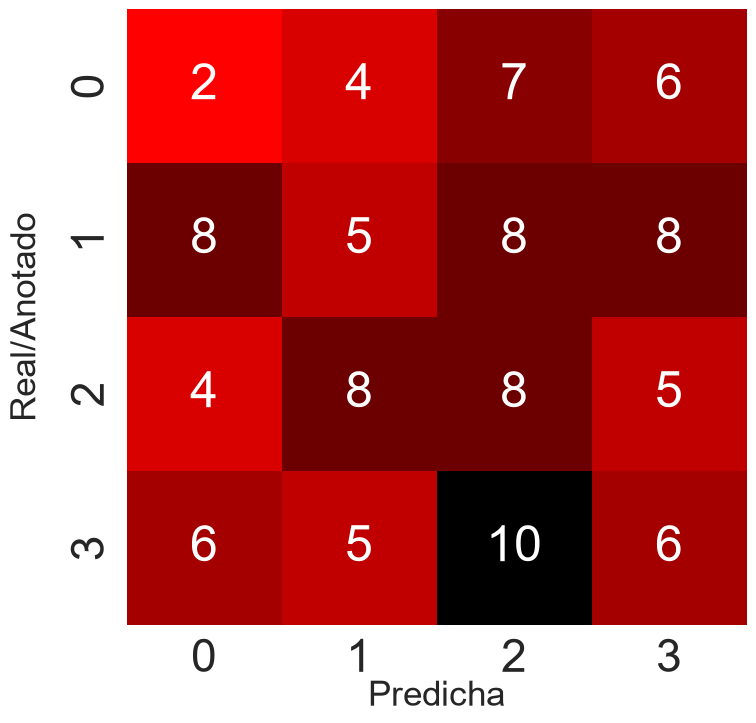

In [6]:

import random
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


# Numero de muestras
n = 100  
nclases = 4

# A falta de clasificador y conjunto de datos, creamos anotaciones y predicciones de forma aleatoria
# Vector aleatorio con etiquetas anotadas
y = [random.randint(0, nclases - 1) for _ in range(n)]
print('Anotaciones ' , y)

# Vector aleatorio con etiquetas predichas por un supuesto clasificador
y_pred = [random.randint(0, nclases - 1) for _ in range(n)]
print('Predicciones ' , y_pred)

print('¿Cómo de bien encajan anotación y predicción?')

#Cálculo de métricas
accuracy = accuracy_score(y, y_pred)
#Para más de una clase se define la forma de promediar
precision = precision_score(y, y_pred,average='weighted')
recall = recall_score(y, y_pred,average='weighted')
f1score = f1_score(y, y_pred,average='weighted')

print(f"Accuracy (TP/(n))= {accuracy}")
print(f"Precision (TP/(TP+FP)) = {precision}")
print(f"Recall (TP/(TP+FN)) = {recall}")
print(f"F1 Score (2*(precision*recall)/(precision+recall)) = {f1score}")


conf_matrix = confusion_matrix(y, y_pred)
plt.figure(figsize=(8,8))
sns.set(font_scale = 1.75)#tamaños tipografía
sns.set(font_scale = 3.0)

ax = sns.heatmap(
        conf_matrix, # confusion matrix 2D array 
        annot=True, # Muestra números en las celdas
        fmt='d', # valores enteros
        cbar=False, # sin barra de colores
        cmap='flag', # mapa de colores
        #vmax=175 # contraste de color
    )

#Etiquetas matriz de confusión
label_font = {'size':'25'}
ax.set_xlabel("Predicha", labelpad=-0.75, fontdict=label_font)
ax.set_ylabel("Real/Anotado", labelpad=20, fontdict=label_font)

TAREA: La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje profundo ni para segmentar, ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno

Si no se quedan satisfechos con la segmentación obtenida, es el mundo real, también en el README comento técnicas recientes de segmentación, que podrían despertar su curiosidad.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

In [3]:
import pandas as pd
from skimage.filters import threshold_otsu
from sklearn.metrics import confusion_matrix, accuracy_score

im = cv2.imread('MPs_test.jpg')
lab = cv2.cvtColor(im, cv2.COLOR_BGR2LAB).astype(np.float32)

# 1) Segmentar: distancia de color al fondo (mediana grande) > 10
bg = np.stack([cv2.resize(cv2.medianBlur(cv2.resize(lab[..., i].astype(np.uint8), None, fx=.25, fy=.25), 31),
               (lab.shape[1], lab.shape[0])) for i in range(3)], -1).astype(np.float32)
m = (np.sqrt(((lab - bg) ** 2).sum(-1)) > 10).astype(np.uint8) * 255
m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
m[:3] = 0; m[-3:] = 0; m[:, :3] = 0; m[:, -3:] = 0
cs, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

# 2) Dos características por partícula: circularidad y brillo relativo al fondo
rows = []
for c in cs:
    a = cv2.contourArea(c)
    if a < 40: continue
    p = cv2.arcLength(c, True); M = cv2.moments(c)
    mk = np.zeros(m.shape, np.uint8); cv2.drawContours(mk, [c], -1, 255, -1)
    rows.append(dict(cx=M['m10']/M['m00'], cy=M['m01']/M['m00'], area=a,
                     circ=4*np.pi*a/p**2,
                     brillo=lab[..., 0][mk > 0].mean() / np.median(lab[..., 0])))
d = pd.DataFrame(rows)

# 3) Reglas: oscuro -> TAR; redondo -> PEL; el resto -> FRA
th = threshold_otsu(d[d.area >= 100].brillo.values)
d['pred'] = np.where(d.brillo < th, 'TAR', np.where(d.circ > 0.76, 'PEL', 'FRA'))

# 4) Evaluación con las anotaciones
ann = pd.read_csv('MPs_test_bbs.csv'); y, yp = [], []
for _, r in ann.iterrows():
    k = d[(d.cx > r.x_min) & (d.cx < r.x_max) & (d.cy > r.y_min) & (d.cy < r.y_max)]
    if len(k): y.append(r.label); yp.append(k.pred.iloc[0])
print('Accuracy:', accuracy_score(y, yp))
print(confusion_matrix(y, yp, labels=['FRA', 'PEL', 'TAR']))

Accuracy: 0.6607142857142857
[[38 12 12]
 [ 8 22  6]
 [ 0  0 14]]
